# AppCompass: which Android apps become hits?

**Question:** what makes an Android app successful?

**Data:** Google Play Store Apps (Kaggle, Lavanya Gupta, collected in 2018, license CC BY-SA 4.0). 10,841 apps, one row for each app.
**Citation:** L. Gupta, "Google Play Store Apps," Feb 2019. [Online]. Available: https://www.kaggle.com/lava18/google-play-store-apps

**The story of this notebook**
1. Load the data and look at it
2. Clean the data (every step is a decision)
3. Explore the data (what do the charts say?)
4. Prepare the data for machine learning
5. Train and compare models
6. Check the final model (results, errors and limits)
7. Extra: do the apps form natural groups? (K-Means)
8. Summary

To run it: put `googleplaystore.csv` in your Google Drive (My Drive), then Runtime > Run all. It takes about 3 minutes.

## 1. Load the data and look at it
We load the Kaggle file and look at it before we change anything. The second cell prints the versions of the libraries, so anyone can repeat our run.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

drive.mount('/content/drive')
df = pd.read_csv('/content/drive/MyDrive/googleplaystore.csv')
df_raw = df.copy()      # an untouched copy, for the before and after table
print(df.shape)

(10841, 13)


In [ ]:
import sklearn
print('pandas', pd.__version__, '| numpy', np.__version__, '| scikit-learn', sklearn.__version__)

pandas 2.2.3 | numpy 2.0.2 | scikit-learn 1.6.1


In [ ]:
df.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB


In [ ]:
missing = df.isnull().sum()
print(missing[missing > 0])

Rating            1474
Type                 1
Content Rating       1
Current Ver          8
Android Ver          3
dtype: int64


In [ ]:
print('Exact duplicate rows:', df.duplicated().sum())
print('Repeated app names:', df['App'].duplicated().sum())

Exact duplicate rows: 483
Repeated app names: 1181


**What we see**
- The file has 10,841 rows and 13 columns.
- `Reviews`, `Size`, `Installs` and `Price` are stored as text, not as numbers.
- `Rating` is empty for 1,474 apps.
- There are 483 exact duplicate rows and 1,181 repeated app names.

**What it means:** we have to fix the types, the empty values and the repeated apps before we can trust any chart.

### Data dictionary
The meanings come from the Kaggle page. The last column is what we found in the real file.

| Column | Meaning (Kaggle page) | What we found in the real file |
|---|---|---|
| App | Application name | Some apps appear more than once |
| Category | Category the app belongs to | 33 categories |
| Rating | Overall user rating of the app (as when scraped) | Empty for about 1 app in 7. One broken row has a rating of 19 |
| Reviews | Number of user reviews for the app | Stored as text |
| Size | Size of the app | Text like `19M`, `201k` or `Varies with device` |
| Installs | Number of user downloads/installs for the app | Text ranges like `1,000,000+` |
| Type | Paid or Free | One value is empty |
| Price | Price of the app | Text like `$4.99` |
| Content Rating | Age group the app is targeted at | The page says "Children / Mature 21+ / Adult", but the real values are Everyone, Teen, Everyone 10+, Mature 17+, Adults only 18+ and Unrated |
| Genres | An app can belong to several genres, apart from its main category | Several genres in one cell, separated by `;` |
| Last Updated | Not described on the page. It looks like the date of the last update | Text like `January 7, 2018` |
| Current Ver | Not described on the page. It looks like the current app version | Text |
| Android Ver | Not described on the page. It looks like the minimum Android version | Text like `4.0.3 and up` |

## 2. Clean the data
Every cleaning step is a decision. For each one we write what we found, what we decided and why.

### 2.1 One broken row
In the column `Installs` one app has the value `Free`. That is not a number of installs, so we look at the whole row.

In [ ]:
df[df['Installs'] == 'Free']

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3.0M,"1,000+",Free,0,Everyone,NaN,"February 11, 2018",1.0.19,4.0 and up,NaN


**What we see:** the values of this row are shifted one column to the left. `Category` is "1.9", `Rating` is 19 and `Reviews` is "3.0M".

**Decision:** remove the row. We cannot know the real values, so changing them would be a guess.

In [ ]:
df = df[df['Installs'] != 'Free'].copy()
print(len(df))

10840


### 2.2 Text to numbers
`Reviews`, `Installs` and `Price` are text (like "1,000,000+" or "$4.99"). We remove the symbols and change the type. We do not hide errors: if a strange value is left, Python stops with an error.

In [ ]:
df['Reviews'] = pd.to_numeric(df['Reviews'])
df['Installs'] = df['Installs'].str.replace('+', '', regex=False).str.replace(',', '', regex=False).astype(int)
df['Price'] = df['Price'].str.replace('$', '', regex=False).astype(float)
print(df[['Reviews', 'Installs', 'Price']].dtypes)

Reviews       int64
Installs      int64
Price       float64
dtype: object


Some apps have a very high price. We look at the ones above 100 dollars.

In [ ]:
df[df['Price'] > 100][['App', 'Price', 'Installs', 'Rating']]

,App,Price,Installs,Rating
4197,most expensive app (H),399.99,100,4.3
4362,💎 I'm rich,399.99,10000,3.8
4367,I'm Rich - Trump Edition,400.00,10000,3.6
5351,I am rich,399.99,100000,3.8
5354,I am Rich Plus,399.99,10000,4.0
5355,I am rich VIP,299.99,10000,3.8
5356,I Am Rich Premium,399.99,50000,4.1
5357,I am extremely Rich,379.99,1000,2.9
5358,I am Rich!,399.99,1000,3.8
5359,I am rich(premium),399.99,5000,3.5


**What we see:** 20 apps cost more than 100 dollars (the highest is 400). 17 of them look like novelty apps ("I am rich" and similar). The other 3 have almost no installs (0 or 1).

**Decision:** keep them. They look like real listings, but they can distort the mean price, so we use the median when we talk about prices.

### 2.3 Size
`M` means megabytes and `k` means kilobytes. `Varies with device` has no number. First we count each kind.

In [ ]:
print('in M:', df['Size'].str.endswith('M').sum())
print('in k:', df['Size'].str.endswith('k').sum())
print('Varies with device:', (df['Size'] == 'Varies with device').sum())
print('all rows:', len(df))

in M: 8829
in k: 316
Varies with device: 1695
all rows: 10840


**Decision:** divide the `k` values by 1024, so every size is in MB, and leave `Varies with device` empty. We do not guess a size.

In [ ]:
size = df['Size'].replace('Varies with device', np.nan)      # no number, so it stays empty
number = size.str[:-1].astype(float)                          # cut the M or the k
in_k = size.str.endswith('k', na=False)
df['Size'] = np.where(in_k, number / 1024, number)            # k to MB
print(df['Size'].describe().round(2))

count    9145.00
mean       21.52
std        22.59
min         0.01
25%         4.90
50%        13.00
75%        30.00
max       100.00
Name: Size, dtype: float64


**What we see:** the biggest app is now 100 MB. 1,227 apps have no size.

### 2.4 Content rating and type
The Kaggle page lists other content ratings than the file. We trust the real file.

**Decision:** remove the 2 apps with the content rating `Unrated` and the 1 app with no `Type`. They are only a few rows.

In [ ]:
df['Content Rating'].value_counts()

Content Rating
Everyone           8714
Teen               1208
Mature 17+          499
Everyone 10+        414
Adults only 18+       3
Unrated               2
Name: count, dtype: int64

In [ ]:
df = df[df['Content Rating'] != 'Unrated'].copy()
print(len(df))

10838


In [ ]:
df['Type'].value_counts(dropna=False)

Type
Free    10037
Paid      800
NaN         1
Name: count, dtype: int64

In [ ]:
df = df[df['Type'].notnull()].copy()
print(df['Type'].value_counts())

Type
Free    10037
Paid      800
Name: count, dtype: int64


### 2.5 Repeated apps
Some apps appear more than once (for example Instagram), each copy with a different number of reviews. If we keep all of them, the same app is counted many times.

**Decision:** keep the copy with the most reviews. If two copies have the same number of reviews, the first one stays. `kind='stable'` makes this the same on every computer.

In [ ]:
before = len(df)
df = df.sort_values('Reviews', ascending=False, kind='stable')    # the copy with the most reviews first
df = df.drop_duplicates(subset='App')                              # keep the first copy of every app
df = df.sort_index()                                               # back to the original order
print('Rows removed:', before - len(df))
print('Repeated app names now:', df['App'].duplicated().sum())

Rows removed: 1181
Repeated app names now: 0


**What we see:** we removed 1,181 rows and no repeated app names are left.

### 2.6 Missing ratings
About 1 app in 7 has no rating. First we check if the apps without a rating look like the others.

In [ ]:
has_rating = df['Rating'].notnull()
print('Median reviews, apps WITH a rating:', df.loc[has_rating, 'Reviews'].median())
print('Median reviews, apps WITHOUT a rating:', df.loc[~has_rating, 'Reviews'].median())

Median reviews, apps WITH a rating: 3017.0
Median reviews, apps WITHOUT a rating: 1.0


**What we see:** the apps without a rating have a median of 1 review, against 3,017 for the apps with a rating. They are tiny apps, so the ratings are not missing at random. Any rating we fill in is only a guess.

**Decision:** fill them with the median rating (4.3) so every app can be used, and mark them in the column `Rating_was_missing`.

**Risk:** this invents 1,461 ratings. So every chart about ratings uses only the real ones, and the model does not use the rating at all.

In [ ]:
df['Rating_was_missing'] = df['Rating'].isnull()      # mark them before we fill
print('Marked:', df['Rating_was_missing'].sum())

median_rating = df['Rating'].median()
df['Rating'] = df['Rating'].fillna(median_rating)
print('Filled with the median:', median_rating)

Marked: 1461
Filled with the median: 4.3


In [ ]:
df = df.reset_index(drop=True)
print(df.shape)
print(df.isnull().sum()[df.isnull().sum() > 0])

(9656, 14)
Size           1227
Current Ver       8
Android Ver       2
dtype: int64


### 2.7 Before and after

In [ ]:
summary = pd.DataFrame({
    'before': [len(df_raw), df_raw['App'].duplicated().sum(), df_raw['Rating'].isnull().sum(), df_raw['Rating'].max(), str(df_raw['Installs'].dtype)],
    'after': [len(df), df['App'].duplicated().sum(), df['Rating'].isnull().sum(), df['Rating'].max(), str(df['Installs'].dtype)]},
    index=['rows', 'repeated app names', 'missing ratings', 'highest rating', 'type of Installs'])
summary

,before,after
rows,10841,9656
repeated app names,1181,0
missing ratings,1474,0
highest rating,19.0,5.0
type of Installs,object,int64


In [ ]:
df[['Rating', 'Reviews', 'Size', 'Installs', 'Price']].describe().round(2)

,Rating,Reviews,Size,Installs,Price
count,9656.00,9656.00,8429.00,9.656000e+03,9656.00
mean,4.19,216871.35,20.40,7.800588e+06,1.10
std,0.50,1831710.75,21.83,5.377791e+07,16.85
min,1.00,0.00,0.01,0.000000e+00,0.00
25%,4.00,25.00,4.60,1.000000e+03,0.00
50%,4.30,969.50,12.00,1.000000e+05,0.00
75%,4.50,29467.75,28.00,1.000000e+06,0.00
max,5.00,78158306.00,100.00,1.000000e+09,400.00


**What we see:** 10,841 rows became 9,656. We removed 1,185 rows (10.9%): 1 broken row, 2 "Unrated", 1 with no Type and 1,181 repeated apps. The highest rating is now 5 (it was 19), and the four text columns are numbers.

**Issues we did not fix, and why**
- **Filled ratings:** they are guesses. They are marked in `Rating_was_missing`.
- **Installs are ranges** (like "1,000+"), so totals are a lower limit.
- **Size is empty** for the "Varies with device" apps. We do not guess.
- **Very high prices:** we kept them (see 2.2).
- **Repeated apps:** only one copy is left (the one with the most reviews).
- **Old data:** collected in 2018, so today's store may look different.

We also save the clean data, so it can be used without running the cleaning again.

In [ ]:
df.to_csv('/content/drive/MyDrive/googleplaystore_clean.csv', index=False)
print('Saved:', df.shape)

Saved: (9656, 14)


## 3. Explore the data
We use two ways to measure success: a high **rating** and many **installs**.

### 3.0 The shape of the number columns
First we look at how the numbers are spread: the mean, the median and the skew (a big positive skew means a long tail of giant values).

In [ ]:
number_table = df[['Rating', 'Reviews', 'Size', 'Installs', 'Price']]
print(number_table.agg(['mean', 'median', 'skew']).round(2))

        Rating    Reviews   Size    Installs  Price
mean      4.19  216871.35  20.40  7800587.81   1.10
median    4.30     969.50  12.00   100000.00   0.00
skew     -1.98      26.57   1.65       15.03  22.53


**What we see:** `Reviews`, `Installs` and `Price` are extremely skewed. The mean is far above the median: Reviews 216,871.3 against 969.5, Installs 7,800,587.8 against 100,000, Price 1.10 against 0. A few giant apps (and a few very expensive ones) pull the mean. `Rating` is skewed the other way (skew -1.98): a few very low ratings pull it down.

**What it means:** for these columns we talk about the median, not the mean. We use rank correlation (Spearman), log scales in the charts, and the log of the price in the model.

For the charts about ratings we use only the 8,195 apps with a real rating. We call this table `real`.

### 3.1 Ratings
**Question:** what does a typical rating look like?

In [ ]:
# apps with a real rating (the filled ratings are guesses, so we leave them out of rating charts)
real = df[~df['Rating_was_missing']].copy()
print(len(real))
real['Rating'].describe().round(3)

8195


count    8195.000
mean        4.173
std         0.536
min         1.000
25%         4.000
50%         4.300
75%         4.500
max         5.000
Name: Rating, dtype: float64

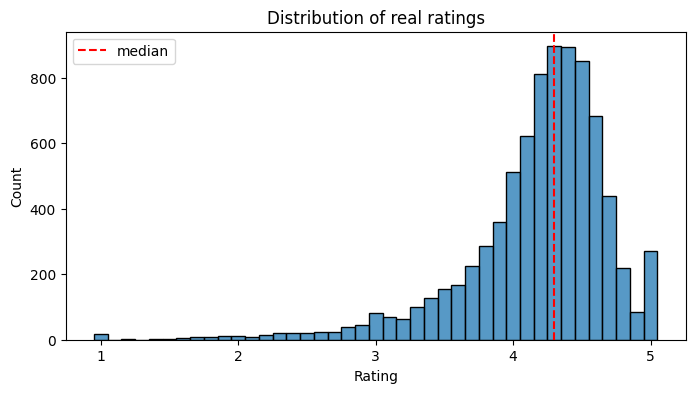

In [ ]:
plt.figure(figsize=(8, 4))
sns.histplot(real['Rating'], binwidth=0.1, binrange=(0.95, 5.05))      # one bar for every rating value
plt.axvline(real['Rating'].median(), color='red', linestyle='--', label='median')
plt.title('Distribution of real ratings')
plt.xlabel('Rating')
plt.legend()
plt.show()

In [ ]:
print('share rated 4.5 or more:', round((real['Rating'] >= 4.5).mean(), 3))
print('share rated below 3.0:', round((real['Rating'] < 3.0).mean(), 3))
print(real['Rating'].value_counts().sort_index().tail(8))

share rated 4.5 or more: 0.311
share rated below 3.0: 0.034
Rating
4.3    895
4.4    894
4.5    851
4.6    684
4.7    439
4.8    220
4.9     85
5.0    271
Name: count, dtype: int64


**About the chart:** ratings come in steps of 0.1 (4.2, 4.3, 4.4 ...). With the default bins some bars hold two rating values and others only one, and this can show a fake spike. Here we use one bar for every value.

**What we see**
- The median rating is 4.3 and the middle half of the apps are between 4.0 and 4.5. The mean (4.17) is a little lower than the median because a few apps have very low ratings.
- 31.1% of the rated apps have 4.5 or more, and only 3.4% are below 3.0.
- There is a small bump at 5.0: 271 apps are rated exactly 5.0, more than the apps rated 4.9 (85) or 4.8 (220).

**What it means:** most apps are rated well. A high rating (4.5 or more) is reached by about 3 apps in 10.

### 3.2 Are perfect ratings the best apps?
**Question:** are the apps with a perfect 5.0 really the best?

In [ ]:
perfect = real[real['Rating'] == 5.0]
print('apps rated 5.0:', len(perfect))
print('median reviews of these apps:', perfect['Reviews'].median())
print('median reviews of all rated apps:', real['Reviews'].median())

apps rated 5.0: 271
median reviews of these apps: 4.0
median reviews of all rated apps: 3017.0


**What we see:** the 271 apps rated 5.0 have a median of **4 reviews**. For all rated apps the median is **3,017 reviews**.

**What it means:** a 5.0 rating mostly means that very few people rated the app. With 4 reviews, one happy user is enough for a perfect score.

**Careful:** we only looked at the median. Some of these apps may really be good.

### 3.3 Is a rating more reliable with more reviews?
**Question:** does the rating become more stable when an app has more reviews?

In [ ]:
bins = [-1, 10, 100, 1000, 10000, 100000, np.inf]
labels = ['0-10', '11-100', '101-1k', '1k-10k', '10k-100k', '100k+']
real['review_group'] = pd.cut(real['Reviews'], bins=bins, labels=labels)

bucket_table = real.groupby('review_group', observed=True)['Rating'].agg(['count', 'mean', 'median', 'std']).round(2)
bucket_table

,count,mean,median,std
review_group,,,,
0-10,632,4.20,4.5,0.95
11-100,1273,4.04,4.2,0.71
101-1k,1488,4.04,4.1,0.56
1k-10k,1529,4.14,4.2,0.44
10k-100k,1822,4.24,4.3,0.32
100k+,1451,4.37,4.4,0.24


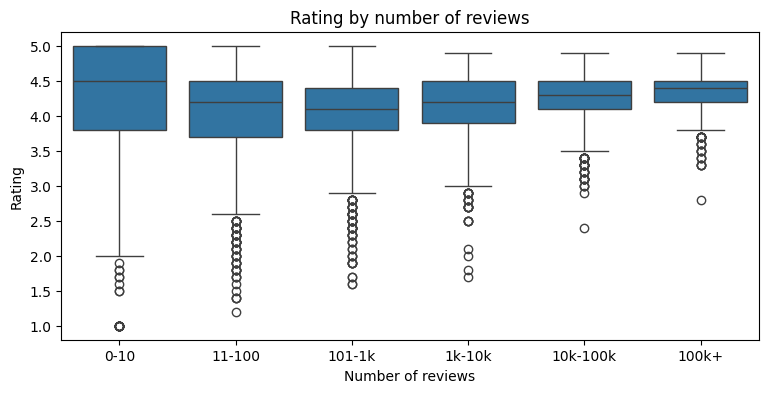

share with 10+ reviews: 0.928
share with 100+ reviews: 0.769


In [ ]:
plt.figure(figsize=(9, 4))
sns.boxplot(data=real, x='review_group', y='Rating')
plt.title('Rating by number of reviews')
plt.xlabel('Number of reviews')
plt.show()
print('share with 10+ reviews:', round((real['Reviews'] >= 10).mean(), 3))
print('share with 100+ reviews:', round((real['Reviews'] >= 100).mean(), 3))

**What we see**
- The spread of the ratings (the `std` column) goes down every time the number of reviews goes up: 0.95, 0.71, 0.56, 0.44, 0.32 and 0.24. In the boxplot the box for 0-10 reviews is very wide and the box for 100k+ is narrow.
- The average rating is lowest for apps with 11 to 1,000 reviews (4.04) and highest for apps with more than 100,000 reviews (4.37).
- 92.8% of the rated apps have at least 10 reviews, and 76.9% have at least 100.

**What it means:** ratings of apps with very few reviews are noisy. This is the main reason why we do not use the rating as the target of our model.

**Careful:** popular apps have higher ratings, but this is only a correlation. We cannot say that a high rating brings more users, or the other way around.

### 3.4 Categories
**Question:** which categories have the most apps, and which get the most installs?

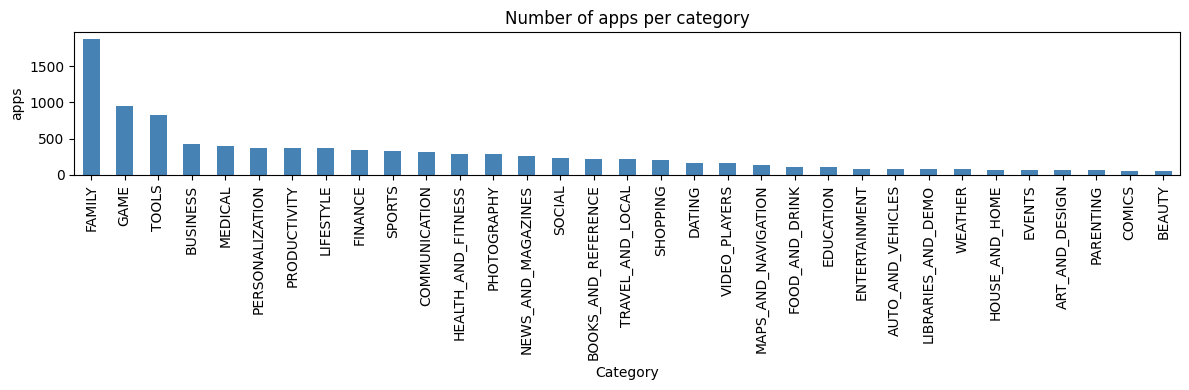

In [ ]:
plt.figure(figsize=(12, 4))
df['Category'].value_counts().plot(kind='bar', color='steelblue')
plt.title('Number of apps per category')
plt.ylabel('apps')
plt.tight_layout()
plt.show()

In [ ]:
cat = df.groupby('Category')['Installs'].agg(apps='count', median='median', total='sum')
cat = cat.sort_values('total', ascending=False)
cat.head(10)

,apps,median,total
Category,,,
GAME,946,1000000.0,13457924415
COMMUNICATION,315,100000.0,11038276251
TOOLS,828,50000.0,8102721915
FAMILY,1872,50000.0,6221541005
PRODUCTIVITY,374,100000.0,5793091369
SOCIAL,239,100000.0,5487867902
PHOTOGRAPHY,281,1000000.0,4658147655
VIDEO_PLAYERS,164,1000000.0,3931902720
TRAVEL_AND_LOCAL,219,100000.0,2894887146


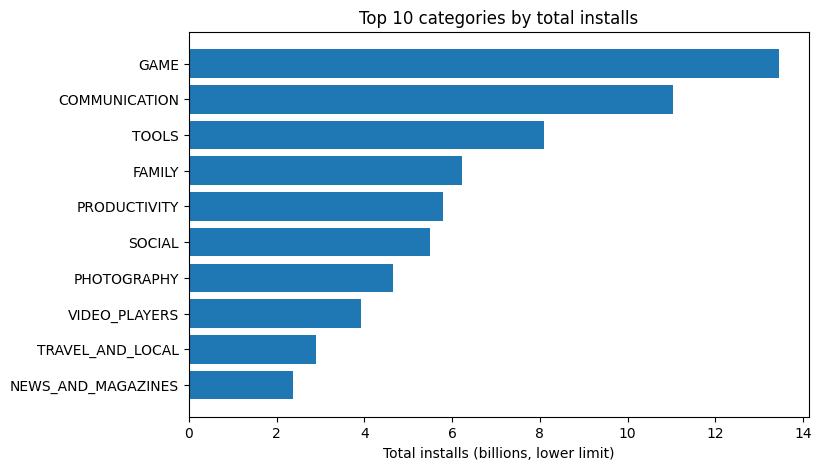

In [ ]:
top10 = cat.head(10).sort_values('total')
plt.figure(figsize=(8, 5))
plt.barh(top10.index, top10['total'] / 1e9)
plt.xlabel('Total installs (billions, lower limit)')
plt.title('Top 10 categories by total installs')
plt.show()

In [ ]:
total_installs = df['Installs'].sum()
print('all installs:', round(total_installs / 1e9, 1), 'billion')

top2 = cat.loc[['GAME', 'COMMUNICATION']]
print('GAME + COMMUNICATION:', round(top2['total'].sum() / total_installs * 100, 1), '% of installs and',
      round(top2['apps'].sum() / len(df) * 100, 1), '% of apps')

# average installs per app against the median (a big number means a few giant apps)
cat['mean'] = (cat['total'] / cat['apps']).round(0)
cat['mean / median'] = (cat['mean'] / cat['median']).round(0)
cat.head(10)

all installs: 75.3 billion
GAME + COMMUNICATION: 32.5 % of installs and 13.1 % of apps


,apps,median,total,mean,mean / median
Category,,,,,
GAME,946,1000000.0,13457924415,14226136.0,14.0
COMMUNICATION,315,100000.0,11038276251,35042147.0,350.0
TOOLS,828,50000.0,8102721915,9785896.0,196.0
FAMILY,1872,50000.0,6221541005,3323473.0,66.0
PRODUCTIVITY,374,100000.0,5793091369,15489549.0,155.0
SOCIAL,239,100000.0,5487867902,22961790.0,230.0
PHOTOGRAPHY,281,1000000.0,4658147655,16577038.0,17.0
VIDEO_PLAYERS,164,1000000.0,3931902720,23975017.0,24.0
TRAVEL_AND_LOCAL,219,100000.0,2894887146,13218663.0,132.0


**What we see**
- FAMILY has the most apps (1,872), then GAME (946) and TOOLS (828).
- GAME (13.5 billion installs) and COMMUNICATION (11.0 billion) have the most installs in total.
- COMMUNICATION has only 315 apps but is second in total installs. Its median is 100,000 installs but its mean is about 35 million, so a few giant apps make most of the total.
- GAME and COMMUNICATION together have 32.5% of all installs but only 13.1% of the apps.
- FAMILY is crowded: many apps, but a median of only 50,000 installs. PHOTOGRAPHY and VIDEO_PLAYERS have a median of 1,000,000 installs with only 281 and 164 apps.

**What it means:** the category matters, and the total and the typical app tell different stories. A category can look big only because of a few giant apps.

**Careful:** installs are ranges (a lower limit) and the data is from 2018.

### 3.5 Free and paid apps
**Question:** how many apps are paid, and are they different from the free apps?

In [ ]:
print(df['Type'].value_counts())
print(df['Type'].value_counts(normalize=True).round(3))
df.groupby('Type')['Installs'].agg(apps='count', median='median', mean='mean')

Type
Free    8902
Paid     754
Name: count, dtype: int64
Type
Free    0.922
Paid    0.078
Name: proportion, dtype: float64


,apps,median,mean
Type,,,
Free,8902,100000.0,8.454854e+06
Paid,754,1000.0,7.607929e+04


In [ ]:
print(real.groupby('Type')['Rating'].agg(['count', 'mean', 'median']).round(2))
print(real.groupby('Type')['Rating'].apply(lambda r: (r >= 4.5).mean()).round(3))

      count  mean  median
Type                     
Free   7593  4.17     4.3
Paid    602  4.26     4.4
Type
Free    0.301
Paid    0.435
Name: Rating, dtype: float64


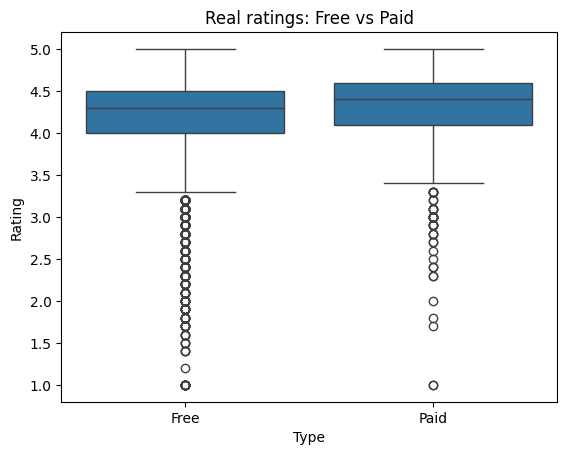

In [ ]:
sns.boxplot(data=real, x='Type', y='Rating')
plt.title('Real ratings: Free vs Paid')
plt.show()

In [ ]:
# does the gap stay when we keep only apps with 100 reviews or more?
print(real[real['Reviews'] >= 100].groupby('Type')['Rating'].agg(['count', 'mean', 'median']).round(2))

      count  mean  median
Type                     
Free   5933  4.19     4.3
Paid    367  4.35     4.4


**What we see**
- 8,902 apps are free (92.2%) and 754 are paid (7.8%).
- Paid apps reach far fewer users: the median is 1,000 installs for paid apps and 100,000 for free apps (100 times less).
- Paid apps have a slightly higher rating: median 4.4 against 4.3 (mean 4.26 against 4.17). The gap stays when we keep only apps with at least 100 reviews (mean 4.35 against 4.19).
- 43.5% of the paid apps are rated 4.5 or more, against 30.1% of the free apps.

**What it means:** a price is a big barrier for installs, and paid apps are rated a bit better.

**Careful:** this does not show that charging money makes an app better. People who choose to pay may rate more kindly. Only 602 paid apps have a real rating, so these numbers are less certain.

### 3.6 Reviews and installs
**Question:** do apps with more installs also have more reviews?

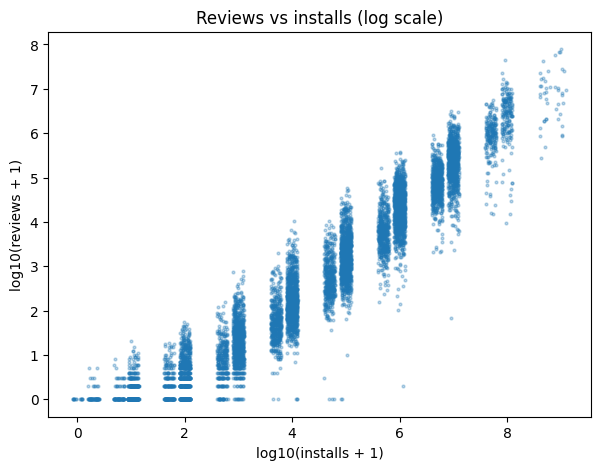

In [ ]:
x = np.log10(df['Installs'] + 1)
y_reviews = np.log10(df['Reviews'] + 1)

plt.figure(figsize=(7, 5))
plt.scatter(x + np.random.uniform(-0.1, 0.1, len(x)), y_reviews, s=4, alpha=0.3)    # a little jitter, installs come in steps
plt.xlabel('log10(installs + 1)')
plt.ylabel('log10(reviews + 1)')
plt.title('Reviews vs installs (log scale)')
plt.show()

In [ ]:
print(df[['Reviews', 'Installs']].corr(method='spearman').round(3))
print(df[['Reviews', 'Installs']].corr(method='pearson').round(3))

          Reviews  Installs
Reviews     1.000     0.968
Installs    0.968     1.000
          Reviews  Installs
Reviews     1.000     0.625
Installs    0.625     1.000


**What we see**
- The points go up in a clear band: more installs, more reviews. The vertical stripes appear because installs come in steps (1,000+, 10,000+ ...).
- The rank correlation (Spearman) is 0.968. The normal correlation (Pearson) is only 0.625.

**What it means:** the two columns carry almost the same information. Pearson is lower because a few giant apps pull the line. Spearman uses only the order of the values, so it is better for skewed numbers like these.

**Careful:** installs probably lead to reviews (people review after installing), not the other way around.

### 3.7 Correlation between the number columns
**Question:** which number columns move together? (real ratings only)

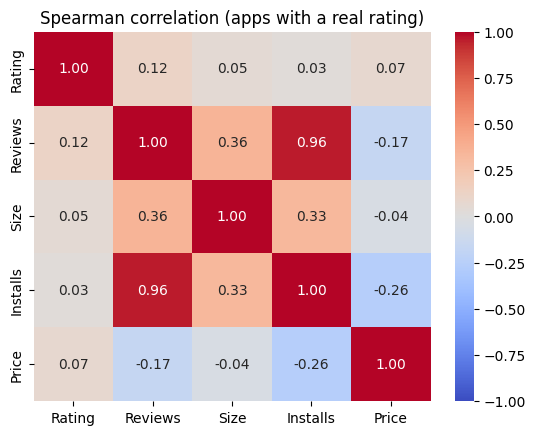

In [ ]:
numbers = real[['Rating', 'Reviews', 'Size', 'Installs', 'Price']]
sns.heatmap(numbers.corr(method='spearman'), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Spearman correlation (apps with a real rating)')
plt.show()

**What we see**
- Reviews and Installs: 0.96, almost the same signal.
- Reviews and Size: 0.36, Installs and Size: 0.33. Bigger apps have a little more installs and reviews.
- Installs and Price: -0.26, Reviews and Price: -0.17. More expensive apps have fewer installs.
- Rating is almost unrelated to every other number column (0.12 or lower).

**What it means:** size, price and popularity alone say very little about whether an app is well rated.

**Careful:** a correlation is not a cause. Price has many zeros (free apps), so the -0.26 mostly shows the difference between free and paid apps, not a smooth effect of the price.

### 3.8 What the exploration told us

| # | What we found | Evidence |
|---|---|---|
| 1 | A rating is not reliable when an app has few reviews | 271 apps rated 5.0 have a median of 4 reviews; the spread of ratings falls from 0.95 to 0.24 |
| 2 | A few categories get a big part of the installs | GAME + COMMUNICATION: 32.5% of installs, 13.1% of apps |
| 3 | Paid apps are rare and reach far fewer users | 7.8% of apps; median 1,000 against 100,000 installs |
| 4 | Reviews follow installs closely | Spearman correlation 0.968 |
| 5 | Rating is almost unrelated to the other number columns | all 0.12 or lower |

**What we do with this:** because of 1 and 5, we do not predict the rating. We predict **installs**, a clearer measure of success. Because of 4, we do not give the model the number of reviews.

## 4. Prepare the data for machine learning

### Our decisions

| # | Decision | Why |
|---|---|---|
| 1 | **Target:** popular = 1,000,000 installs or more | Installs are a clearer measure of success than ratings, and 1 million is a clear line |
| 2 | **Features:** only things about the app itself | We want to know what about an app goes together with success |
| 3 | **No Reviews and no Rating as features** | Reviews appear after people install the app, so they are too close to the target (we test this in 6.6) |
| 4 | **Split first,** and fit every step on the training data only | To avoid data leakage |
| 5 | **Main metric: F1** (also accuracy, precision, recall and AUC) | A model that always says "not popular" is already right 64.8% of the time |

### 4.1 The target

In [ ]:
# 1 = popular app (1,000,000 installs or more)
df['popular'] = (df['Installs'] >= 1_000_000).astype(int)
print(df['popular'].value_counts())
print(df['popular'].value_counts(normalize=True).round(3))

popular
0    6258
1    3398
Name: count, dtype: int64
popular
0    0.648
1    0.352
Name: proportion, dtype: float64


**What we see:** 3,398 of the 9,656 apps (35.2%) are popular and 6,258 are not.

**What it means:** a model that always says "not popular" is right 64.8% of the time. This is the baseline every model has to beat.

**Careful:** `Installs` is a range, so the line at one million is approximate.

### 4.2 The features
Each feature has a reason. We make them one by one.

**Paid or free, and the price.** Paid apps get far fewer installs (3.5). The price is very skewed (3.0), so we use its log.

In [ ]:
# paid or free, and the price (log, because prices are very skewed)
df['is_paid'] = (df['Type'] == 'Paid').astype(int)
df['log_price'] = np.log1p(df['Price'])

**Content rating.** The age groups have a natural order, so we turn them into numbers from 0 to 4.

In [ ]:
# content rating as an ordered number
age_order = {'Everyone': 0, 'Everyone 10+': 1, 'Teen': 2, 'Mature 17+': 3, 'Adults only 18+': 4}
df['content_rating_num'] = df['Content Rating'].map(age_order)

**Days since the last update.** Apps that are still updated may be more popular. We count from the newest date in the data (8 August 2018). This is one fixed date, so nothing from the test set leaks into the feature.

In [ ]:
# days since the last update (counted from the newest date in the data)
dates = pd.to_datetime(df['Last Updated'], format='%B %d, %Y')
df['days_since_update'] = (dates.max() - dates).dt.days

**Minimum Android version.** A lower version runs on more phones. We take the first number from text like "4.0.3 and up".

In [ ]:
# minimum Android version: '4.0.3 and up' becomes 4.0, 'Varies with device' stays empty
df['min_android'] = df['Android Ver'].str.extract(r'(\d+\.?\d*)')[0].astype(float)

**The final list.** Six number columns and the category.

| Feature | Made from | Why |
|---|---|---|
| `Category` | `Category` | The categories are very different in installs (3.4) |
| `Size` | `Size` | The size in MB. "Varies with device" stays empty and becomes its own signal |
| `is_paid` | `Type` | Paid apps get far fewer installs (3.5) |
| `log_price` | `Price` | The price, as a log because it is very skewed |
| `content_rating_num` | `Content Rating` | The age group as an ordered number |
| `days_since_update` | `Last Updated` | Apps that are still updated may be more popular |
| `min_android` | `Android Ver` | A lower version runs on more phones |

**Columns we do not use:** `App` (a different name in every row), `Current Ver` (messy text), `Genres` (overlaps with Category), `Reviews` and `Rating` (decision 3), `Rating_was_missing` (it comes from Rating).

In [ ]:
number_cols = ['Size', 'is_paid', 'log_price', 'content_rating_num', 'days_since_update', 'min_android']
category_cols = ['Category']

X = df[number_cols + category_cols]
y = df['popular']
print(X.isnull().sum())

Size                  1227
is_paid                  0
log_price                0
content_rating_num       0
days_since_update        0
min_android            992
Category                 0
dtype: int64


**What we see:** `Size` is empty for 1,227 apps and `min_android` for 992 apps ("Varies with device"). The pipeline below fills them with the median of the training data and adds a column that says the value was empty.

### 4.3 Split first
We use 80% of the apps for training and 20% for testing. We use `stratify`, so both parts keep the same share of popular apps. The test set is not touched until the end.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)
print(round(y_train.mean(), 3), round(y_test.mean(), 3))

(7724, 7) (1932, 7)
0.352 0.352


**What we see:** 7,724 apps for training and 1,932 for testing. The share of popular apps is 35.2% in both.

### 4.4 The preprocessing pipeline
Everything that learns from the data (the median, the scaling, the one-hot columns) goes inside a pipeline. In every cross-validation round these steps are fitted only on the training part of that round. This is how we avoid leakage.

**Why these choices?**
- **Category: one-hot.** The 33 categories have no order (GAME is not "bigger" than TOOLS). Numbers 1, 2, 3 would invent an order, so we make one yes/no column for each category. Categories with less than 1% of the apps share one column, so rare categories do not add noise.
- **Content rating: an ordered number.** The age groups really have an order.
- **Empty values: the median, plus a "was empty" column.** The median is not pulled by giant values. The extra column keeps the information that the value was empty, because "size varies with device" is itself a signal.
- **Scaling only for Logistic Regression and KNN.** They use distances or a straight line, so a column with big numbers would dominate. Trees do not care about the scale.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

def make_prep(scale):
    # numbers: fill empty values with the median (and add a 'was empty' column), then scale if the model needs it
    number_steps = [('fill', SimpleImputer(strategy='median', add_indicator=True))]
    if scale:
        number_steps.append(('scale', StandardScaler()))
    return ColumnTransformer([
        ('numbers', Pipeline(number_steps), number_cols),
        ('category', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=0.01, sparse_output=False), category_cols)])

### 4.5 Is the data ready for modeling?
Before we train anything we check the data that the models will receive. We fit the preprocessing on the training data only and look at the result.

In [ ]:
prep_check = make_prep(True).fit(X_train)            # fitted on the training data only
train_ready = prep_check.transform(X_train)
test_ready = prep_check.transform(X_test)
names = prep_check.get_feature_names_out()

print('columns before:', X_train.shape[1], '| columns after:', train_ready.shape[1])
print('one-hot columns for Category:', sum(name.startswith('category__') for name in names))
print('data type of every column:', train_ready.dtype)
print('missing values after (train + test):', np.isnan(train_ready).sum() + np.isnan(test_ready).sum())
print('train rows:', train_ready.shape[0], '| test rows:', test_ready.shape[0])
print('rows in both train and test:', len(set(X_train.index) & set(X_test.index)))
print('app names in both train and test:', len(set(df.loc[X_train.index, 'App']) & set(df.loc[X_test.index, 'App'])))

columns before: 7 | columns after: 33
one-hot columns for Category: 25
data type of every column: float64
missing values after (train + test): 0
train rows: 7724 | test rows: 1932
rows in both train and test: 0


app names in both train and test: 0


In [ ]:
# scaled numbers: mean 0 and std 1 on the training data. The test data is scaled with the training numbers.
scaled = pd.DataFrame(train_ready, columns=names)[['numbers__Size', 'numbers__days_since_update']]
scaled_test = pd.DataFrame(test_ready, columns=names)[['numbers__Size', 'numbers__days_since_update']]
print(pd.DataFrame({'train mean': scaled.mean(), 'train std': scaled.std(), 'test mean': scaled_test.mean(), 'test std': scaled_test.std()}).round(2))

                            train mean  train std  test mean  test std
numbers__Size                     -0.0        1.0       0.05      1.03
numbers__days_since_update         0.0        1.0       0.05      1.06


**What we see**
- Before the pipeline the training data has 7 columns (6 number columns and the text column `Category`). After it there are 33 columns, all numbers.
- `Category` (33 categories) became 25 one-hot columns: one for each category with at least 1% of the apps, and one column for all the rare ones together. Two more columns say that `Size` or `min_android` was empty.
- No missing values are left (0).
- 7,724 apps for training and 1,932 for testing. No row and no app name is in both sets (0 and 0).
- The scaled `Size` has mean 0.00 and std 1.00 on the training data. On the test data it is 0.05 and 1.03, because the test data is scaled with the training numbers. This is how it should be.

| | Before | After the pipeline |
|---|---|---|
| Columns | 7 (6 numbers and 1 text) | 33 numbers |
| Empty values | 2,219 (in `Size` and `min_android`) | 0 |
| Category | text, 33 values | 25 one-hot columns |
| Scale (`Size`) | mean 20.18 MB | mean 0.00, std 1.00 |
| Rows | 9,656 | 7,724 training and 1,932 test, no overlap |

**What it means:** the data is ready for modeling. It is all numbers, there are no missing values, and the training and test sets do not overlap.

## 5. Train and compare models
One test split can be lucky. So we compare the models with **5-fold cross-validation**: the training data is cut into 5 parts, and each part is used once for checking while the model learns from the other 4. All models use the same 5 folds, so the comparison is fair.

**Which models and why.** We use a baseline and four models. They go from simple to flexible, and they are the models of this module.
- **Baseline:** always says "not popular". It is the floor: every real model has to be better.
- **Logistic Regression:** simple, fast and easy to explain.
- **KNN:** compares an app with the most similar apps and takes a vote. It needs scaled numbers.
- **Decision Tree:** readable if-then rules.
- **Random Forest:** many trees that vote. It handles mixed features and does not need scaling.

For every model we try a few settings with `GridSearchCV` and keep the setting with the best F1.

In [ ]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import make_scorer, precision_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)    # the same 5 folds for every model

In [ ]:
baseline = Pipeline([('prep', make_prep(True)), ('model', DummyClassifier(strategy='most_frequent'))])

**Logistic Regression.** We try 4 values of `C` (how strict the model is).

In [ ]:
logreg_search = GridSearchCV(
    Pipeline([('prep', make_prep(True)), ('model', LogisticRegression(max_iter=2000))]),
    param_grid={'model__C': [0.01, 0.1, 1, 10]}, cv=cv, scoring='f1')
logreg_search.fit(X_train, y_train)
print(logreg_search.best_params_, round(logreg_search.best_score_, 3))

{'model__C': 10} 0.596


**KNN.** We try 4 numbers of neighbors.

In [ ]:
knn_search = GridSearchCV(
    Pipeline([('prep', make_prep(True)), ('model', KNeighborsClassifier())]),
    param_grid={'model__n_neighbors': [5, 15, 31, 51]}, cv=cv, scoring='f1')
knn_search.fit(X_train, y_train)
print(knn_search.best_params_, round(knn_search.best_score_, 3))

{'model__n_neighbors': 5} 0.631


**Decision Tree.** We try different depths and sizes of leaves.

In [ ]:
tree_search = GridSearchCV(
    Pipeline([('prep', make_prep(False)), ('model', DecisionTreeClassifier(random_state=42))]),
    param_grid={'model__max_depth': [3, 5, 8, 12], 'model__min_samples_leaf': [5, 20]}, cv=cv, scoring='f1')
tree_search.fit(X_train, y_train)
print(tree_search.best_params_, round(tree_search.best_score_, 3))

{'model__max_depth': 8, 'model__min_samples_leaf': 5} 0.617


**Random Forest.** 300 trees. We try different depths and sizes of leaves.

In [ ]:
forest_search = GridSearchCV(
    Pipeline([('prep', make_prep(False)), ('model', RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1))]),
    param_grid={'model__max_depth': [None, 10, 20], 'model__min_samples_leaf': [1, 3, 5]}, cv=cv, scoring='f1')
forest_search.fit(X_train, y_train)
print(forest_search.best_params_, round(forest_search.best_score_, 3))

{'model__max_depth': None, 'model__min_samples_leaf': 3} 0.646


**The best settings:** Logistic Regression C = 10, KNN 5 neighbors, Decision Tree depth 8 with at least 5 apps per leaf, Random Forest with no depth limit and at least 3 apps per leaf.

Now we put the five models together and score each one with the same 5 folds.

In [ ]:
best_models = {
    'Baseline': baseline,
    'Logistic Regression': logreg_search.best_estimator_,
    'KNN': knn_search.best_estimator_,
    'Decision Tree': tree_search.best_estimator_,
    'Random Forest': forest_search.best_estimator_}

In [ ]:
scoring = {'accuracy': 'accuracy', 'precision': make_scorer(precision_score, zero_division=0),
           'recall': 'recall', 'f1': 'f1', 'auc': 'roc_auc'}

rows = []
for name, model in best_models.items():
    r = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    rows.append({'model': name, 'accuracy': r['test_accuracy'].mean(), 'precision': r['test_precision'].mean(),
                 'recall': r['test_recall'].mean(), 'f1': r['test_f1'].mean(), 'f1 std': r['test_f1'].std(), 'auc': r['test_auc'].mean()})

cv_table = pd.DataFrame(rows).set_index('model').round(3)
cv_table

,accuracy,precision,recall,f1,f1 std,auc
model,,,,,,
Baseline,0.648,0.000,0.000,0.000,0.000,0.500
Logistic Regression,0.756,0.716,0.511,0.596,0.009,0.810
KNN,0.749,0.654,0.610,0.631,0.015,0.797
Decision Tree,0.757,0.696,0.557,0.617,0.019,0.794
Random Forest,0.777,0.731,0.580,0.646,0.016,0.843


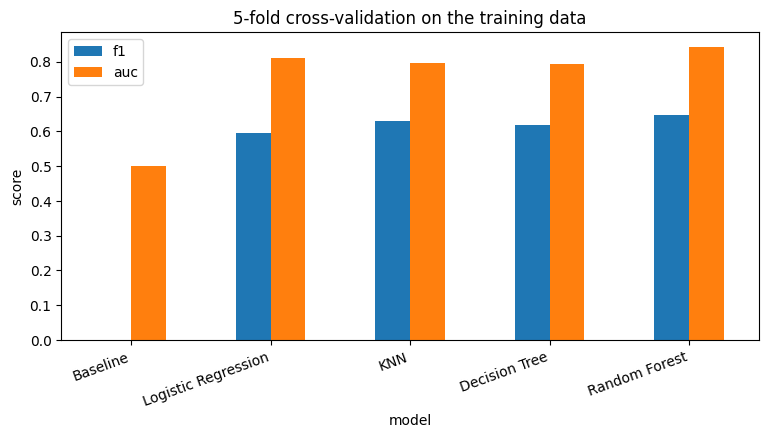

In [ ]:
cv_table[['f1', 'auc']].plot(kind='bar', figsize=(9, 4))
plt.title('5-fold cross-validation on the training data')
plt.ylabel('score')
plt.xticks(rotation=20, ha='right')
plt.show()

**What we see**
- All four models are clearly better than the baseline (accuracy 0.648, AUC 0.500).
- Random Forest is the best on accuracy (0.777), precision (0.731), F1 (0.646) and AUC (0.843).
- KNN has the best recall (0.610) and the second best F1 (0.631). The F1 gap to Random Forest (0.015) is about the size of the spread between folds (0.015 to 0.016), so on F1 alone they are close. On AUC the Random Forest is clearly better (0.843 against 0.797).
- Logistic Regression (F1 0.596) and the Decision Tree (F1 0.617) are in the middle.

**What it means:** we choose the **Random Forest** as the final model, mostly because of its AUC and accuracy.

**Careful:** the settings were chosen with the same folds that give these scores, so the numbers are a little optimistic for every model. This is why we also use the test set, once.

In [ ]:
final_name = cv_table.drop('Baseline')['f1'].idxmax()      # the best cross-validated F1
final_model = best_models[final_name].fit(X_train, y_train)
print('final model:', final_name)

final model: Random Forest


## 6. Check the final model
### 6.1 The test set (used once)
We show the cross-validated scores next to the test scores, so both are visible.

In [ ]:
from sklearn.metrics import accuracy_score, recall_score, f1_score, roc_auc_score, confusion_matrix

pred = final_model.predict(X_test)
proba = final_model.predict_proba(X_test)[:, 1]
test_scores = {'accuracy': accuracy_score(y_test, pred), 'precision': precision_score(y_test, pred), 'recall': recall_score(y_test, pred),
               'f1': f1_score(y_test, pred), 'auc': roc_auc_score(y_test, proba)}

compare = pd.DataFrame({'cross-validation': cv_table.loc[final_name, ['accuracy', 'precision', 'recall', 'f1', 'auc']],
                        'test set (used once)': pd.Series(test_scores)}).round(3)
print('baseline accuracy on the test set:', round(accuracy_score(y_test, baseline.fit(X_train, y_train).predict(X_test)), 3))
compare

baseline accuracy on the test set: 0.648


,cross-validation,test set (used once)
accuracy,0.777,0.783
precision,0.731,0.739
recall,0.580,0.594
f1,0.646,0.659
auc,0.843,0.843


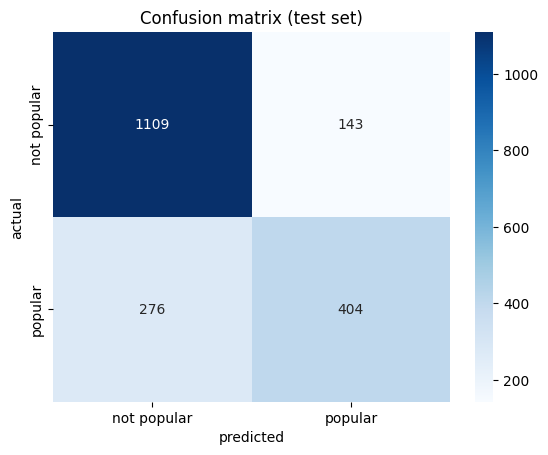

[[1109  143]
 [ 276  404]]


In [ ]:
cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['not popular', 'popular'], yticklabels=['not popular', 'popular'])
plt.xlabel('predicted')
plt.ylabel('actual')
plt.title('Confusion matrix (test set)')
plt.show()
print(cm)

**What we see**
- On the test set the Random Forest has accuracy 0.783, precision 0.739, recall 0.594, F1 0.659 and AUC 0.843. The baseline accuracy is 0.648.
- The test scores are close to the cross-validation scores (F1 0.659 against 0.646, AUC 0.843 against 0.843). This is a good sign: the model is not just lucky on one split.
- There are 680 popular apps in the test set. The model finds 404 of them and misses 276. It says "popular" for 547 apps and is right for 404 of them.

**What it means:** the model is careful. When it says "popular" it is right about 74% of the time.

**One limitation of the final model:** it misses about 4 popular apps in 10 (recall 0.594). Our columns say nothing about brand, marketing or quality, so big hits that look like ordinary apps are not found.

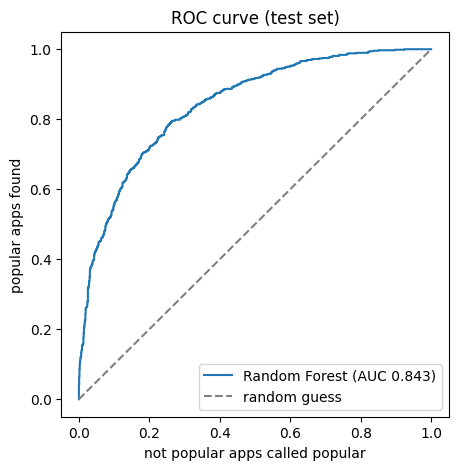

In [ ]:
from sklearn.metrics import roc_curve

fpr, tpr, _ = roc_curve(y_test, proba)
plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label='Random Forest (AUC ' + str(round(test_scores['auc'], 3)) + ')')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='random guess')
plt.xlabel('not popular apps called popular')
plt.ylabel('popular apps found')
plt.title('ROC curve (test set)')
plt.legend()
plt.show()

**What we see:** the ROC curve is far above the dotted line of a random guess, and the AUC is 0.843.

**What it means:** the AUC is the chance that, for a random pair of one popular and one not popular app, the model gives the higher score to the popular one. A coin flip would give 0.5.

In [ ]:
rows = []
for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    guess = (proba >= threshold).astype(int)
    rows.append({'threshold': threshold, 'precision': precision_score(y_test, guess, zero_division=0),
                 'recall': recall_score(y_test, guess), 'f1': f1_score(y_test, guess)})
pd.DataFrame(rows).round(3)

,threshold,precision,recall,f1
0,0.3,0.582,0.831,0.684
1,0.4,0.662,0.712,0.686
2,0.5,0.739,0.594,0.659
3,0.6,0.788,0.463,0.583
4,0.7,0.861,0.354,0.502


**What we see:** the model gives every app a chance of being popular, and we call it popular when the chance is 0.5 or more. A lower threshold finds more popular apps but makes more false alarms: at 0.3 the recall is 0.831 and the precision 0.582. A higher threshold is more careful: at 0.7 the precision is 0.861 and the recall 0.354. The F1 is highest at 0.4 (0.686), but only a little above 0.5 (0.659).

**Careful:** we looked at these numbers on the test set only to show the trade-off. We keep 0.5 as the final threshold. To change it, we would choose it with cross-validation on the training data, not on the test set.

### 6.2 The predictions for single apps
Ten random apps from the test set, with the chance the model gives and what is true.

In [ ]:
examples = df.loc[X_test.index, ['App', 'Category', 'Installs']].copy()
examples['chance of popular'] = proba.round(2)
examples['predicted'] = np.where(pred == 1, 'popular', 'not popular')
examples['actual'] = np.where(y_test.values == 1, 'popular', 'not popular')
examples.sample(10, random_state=42)

,App,Category,Installs,chance of popular,predicted,actual
171,Golden Dictionary (EN-AR),BOOKS_AND_REFERENCE,1000000,0.29,not popular,popular
9448,ORLANDO FLORIDA MAP,TRAVEL_AND_LOCAL,1000,0.11,not popular,not popular
7680,DT Baby Cam,TOOLS,500,0.26,not popular,not popular
7734,Night: DU Launcher Theme,PERSONALIZATION,50000,0.18,not popular,not popular
9588,FQ India,LIFESTYLE,10,0.34,not popular,not popular
7784,GoPlus Cam,VIDEO_PLAYERS,500000,0.38,not popular,not popular
8834,Raytheon F-16 EW 360 VR,FAMILY,500,0.10,not popular,not popular
6298,Zombie Death Shooter,GAME,1000000,0.50,popular,popular
5825,Limbo PC Emulator QEMU ARM x86,TOOLS,1000000,0.29,not popular,popular
3926,AE Blackjack,GAME,100000,0.44,not popular,not popular


**What it means:** the model gives a chance for every app. Some predictions are wrong, which is why we also look at the confusion matrix and at the errors (6.5).

### 6.3 What does the model use?

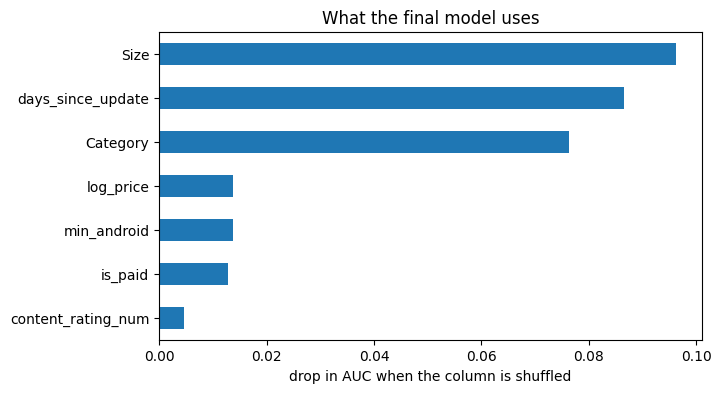

Size                  0.096
days_since_update     0.087
Category              0.076
log_price             0.014
min_android           0.014
is_paid               0.013
content_rating_num    0.005
dtype: float64

In [ ]:
from sklearn.inspection import permutation_importance

result = permutation_importance(final_model, X_test, y_test, scoring='roc_auc', n_repeats=10, random_state=42, n_jobs=-1)
importance = pd.Series(result.importances_mean, index=X_test.columns).sort_values()

importance.plot(kind='barh', figsize=(7, 4))
plt.xlabel('drop in AUC when the column is shuffled')
plt.title('What the final model uses')
plt.show()
importance.sort_values(ascending=False).round(3)

We shuffle one column at a time on the test set and see how much the AUC drops.

**What we see:** `Size` matters most (0.096), then `days_since_update` (0.087) and `Category` (0.076). The price (0.014), the minimum Android version (0.014), `is_paid` (0.013) and the content rating (0.005) matter much less.

**Careful:** this shows what the model uses, not what causes popularity. `is_paid` and `log_price` carry almost the same information, so shuffling one of them hides part of its effect.

To see the direction, we look at the share of popular apps in each group.

In [ ]:
tmp = df.copy()
tmp['update_group'] = pd.cut(tmp['days_since_update'], [-1, 30, 90, 180, 365, 10000],
                             labels=['up to 30 days', '31-90 days', '91-180 days', '181-365 days', 'over 365 days'])
tmp['size_group'] = pd.cut(tmp['Size'], [0, 5, 20, 50, 100], labels=['up to 5 MB', '5-20 MB', '20-50 MB', '50-100 MB'])

for column in ['update_group', 'size_group']:
    print(tmp.groupby(column, observed=True)['popular'].agg(apps='size', share_popular='mean').round(3))
    print()

print('size varies with device:', round(tmp.loc[tmp['Size'].isnull(), 'popular'].mean(), 3),
      '| size known:', round(tmp.loc[tmp['Size'].notnull(), 'popular'].mean(), 3))

               apps  share_popular
update_group                      
up to 30 days  2936          0.567
31-90 days     1828          0.389
91-180 days    1158          0.235
181-365 days   1320          0.229
over 365 days  2414          0.185

            apps  share_popular
size_group                     
up to 5 MB  2316          0.138
5-20 MB     3145          0.270
20-50 MB    2092          0.385
50-100 MB    876          0.589

size varies with device: 0.739 | size known: 0.296


In [ ]:
by_category = tmp.groupby('Category')['popular'].agg(apps='size', share_popular='mean').query('apps >= 100')
by_category = by_category.sort_values('share_popular', ascending=False).round(3)
print(by_category.head(3))
print(by_category.tail(3))

             apps  share_popular
Category                        
PHOTOGRAPHY   281          0.616
EDUCATION     107          0.579
GAME          946          0.571
          apps  share_popular
Category                     
DATING     170          0.194
BUSINESS   420          0.164
MEDICAL    395          0.046


**What we see:** the more recently an app was updated, the more often it is popular: 56.7% of the apps updated in the last 30 days are popular, against 18.5% of the apps not updated for over a year. Bigger apps are more often popular too: 13.8% up to 5 MB and 58.9% between 50 and 100 MB. Apps whose size "varies with device" are popular 73.9% of the time, against 29.6% when the size is known. By category, PHOTOGRAPHY (61.6%), EDUCATION (57.9%) and GAME (57.1%) have the highest share of popular apps, and MEDICAL (4.6%), BUSINESS (16.4%) and DATING (19.4%) the lowest.

**Careful:** these are associations, not causes. Popular apps may be updated more often because they have the resources, and big apps are often rich games or media apps.

### 6.4 More apps or better features?

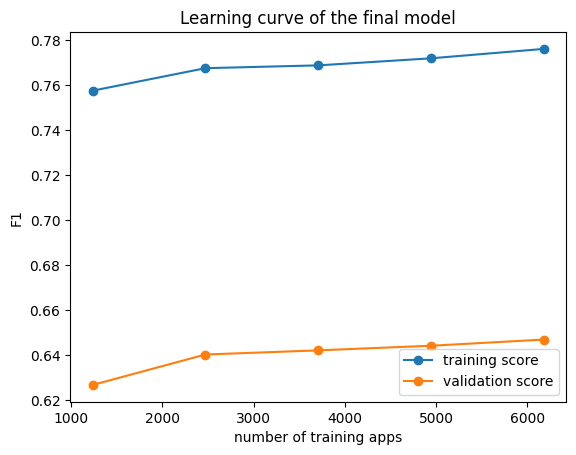

,training apps,train F1,validation F1
0,1235,0.757,0.627
1,2471,0.767,0.640
2,3707,0.769,0.642
3,4943,0.772,0.644
4,6179,0.776,0.647


In [ ]:
from sklearn.model_selection import learning_curve

sizes, train_sc, val_sc = learning_curve(final_model, X_train, y_train, cv=cv, scoring='f1',
                                         train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0], n_jobs=-1)
plt.plot(sizes, train_sc.mean(axis=1), marker='o', label='training score')
plt.plot(sizes, val_sc.mean(axis=1), marker='o', label='validation score')
plt.xlabel('number of training apps')
plt.ylabel('F1')
plt.title('Learning curve of the final model')
plt.legend()
plt.show()
pd.DataFrame({'training apps': sizes, 'train F1': train_sc.mean(axis=1).round(3), 'validation F1': val_sc.mean(axis=1).round(3)})

**What we see:** the validation F1 goes up a little, from 0.627 with 1,235 training apps to 0.647 with 6,179, and the curve is flattening. The training F1 is higher (0.776), so the gap is about 0.13.

**What it means:** the forest memorizes part of the training apps. More apps of the same kind would help only a little. To get much better, we need better features, not only more rows.

### 6.5 Where does the model fail?

In [ ]:
errors = df.loc[X_test.index, ['App', 'Category', 'Type', 'Installs']].copy()
errors['predicted'] = pred
errors['actual'] = y_test.values
errors['wrong'] = (errors['predicted'] != errors['actual']).astype(int)

by_cat = errors.groupby('Category').agg(apps=('wrong', 'size'), error_rate=('wrong', 'mean')).query('apps >= 40')
by_cat = by_cat.sort_values('error_rate', ascending=False).round(3)
print(by_cat)
print()
print(errors.groupby('Type')['wrong'].mean().round(3))

                    apps  error_rate
Category                            
HEALTH_AND_FITNESS    70       0.371
GAME                 196       0.260
COMMUNICATION         78       0.244
SPORTS                66       0.242
TOOLS                157       0.242
PRODUCTIVITY          69       0.232
FAMILY               380       0.226
PERSONALIZATION       79       0.215
TRAVEL_AND_LOCAL      45       0.200
PHOTOGRAPHY           52       0.192
LIFESTYLE             85       0.188
SHOPPING              49       0.184
BUSINESS              86       0.174
FINANCE               70       0.171
SOCIAL                48       0.167
NEWS_AND_MAGAZINES    42       0.119
MEDICAL               88       0.023

Type
Free    0.232
Paid    0.033
Name: wrong, dtype: float64


In [ ]:
# the biggest misses: popular apps that the model called 'not popular'
misses = errors[(errors['actual'] == 1) & (errors['predicted'] == 0)].sort_values('Installs', ascending=False).head(5)
misses[['App', 'Category', 'Installs']]

,App,Category,Installs
1259,PAC-MAN,GAME,100000000
3049,Dubsmash,VIDEO_PLAYERS,100000000
2758,Motorola Gallery,VIDEO_PLAYERS,100000000
1362,Flow Free,GAME,100000000
2500,"Hola Launcher- Theme,Wallpaper",PERSONALIZATION,100000000


**What we see**
- Free apps are wrong 23.2% of the time, paid apps only 3.3%. Paid apps are almost never popular, so they are easy.
- The highest error rates (categories with at least 40 test apps) are HEALTH_AND_FITNESS (37.1%), GAME (26.0%) and COMMUNICATION (24.4%). The lowest are MEDICAL (2.3%), NEWS_AND_MAGAZINES (11.9%) and SOCIAL (16.7%).
- The biggest misses are PAC-MAN, Dubsmash, Motorola Gallery, Flow Free and Hola Launcher- Theme,Wallpaper, with 100 million installs each.

**What it means:** our columns say nothing about brand, marketing or how good the app is, so big hits that look like ordinary apps are missed.

**Careful:** we did not check why the categories differ.

### 6.6 An experiment: what if we add Reviews?

In [ ]:
# Experiment (not our final model): what happens if we ADD Reviews as a feature?
X_leak = df[number_cols + ['Reviews'] + category_cols].copy()
X_leak['Reviews'] = np.log1p(X_leak['Reviews'])
Xl_train, Xl_test = X_leak.loc[X_train.index], X_leak.loc[X_test.index]        # the same split as before

prep_leak = ColumnTransformer([
    ('numbers', Pipeline([('fill', SimpleImputer(strategy='median', add_indicator=True))]), number_cols + ['Reviews']),
    ('category', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=0.01, sparse_output=False), category_cols)])
forest_leak = Pipeline([('prep', prep_leak), ('model', RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1))])
forest_leak.fit(Xl_train, y_train)

leak_auc = roc_auc_score(y_test, forest_leak.predict_proba(Xl_test)[:, 1])
leak_acc = accuracy_score(y_test, forest_leak.predict(Xl_test))
print(f'WITH Reviews -> AUC: {leak_auc:.3f} | accuracy: {leak_acc:.3f}')

WITH Reviews -> AUC: 0.987 | accuracy: 0.950


**What we see:** with Reviews the AUC is 0.987 and the accuracy 0.950. Without it (our final model) they are 0.843 and 0.783.

**What it means:** this is why we left Reviews out. People write reviews after they install an app, so Reviews are a result of installs, not a reason for them. A model with Reviews looks great, but it does not help to understand what makes an app successful.

### 6.7 What this means for a developer
- **Category matters.** PHOTOGRAPHY, EDUCATION and GAME have 57% to 62% popular apps, MEDICAL only 4.6%.
- **Keep the app fresh.** 56.7% of the apps updated in the last 30 days are popular, against 18.5% after a year.
- **A price limits the reach.** The median paid app has 1,000 installs, the median free app 100,000.

**Careful:** these are links in 2018 data, not proof that changing one thing will cause popularity. The model cannot see brand or marketing, which matter a lot.

## 7. Extra: do the apps form natural groups?
So far we used the labels (popular or not). Here we ignore them and let **K-Means** group the apps by their facts only (size, price, content rating, last update, minimum Android). Then we look at each group. K-Means uses distances, so we scale the numbers first. This is only for exploring the data, so we use all the apps and not only the training set.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

segment_data = df[number_cols].copy()
segment_data = segment_data.fillna(segment_data.median())         # fill the empty sizes and versions
segment_scaled = StandardScaler().fit_transform(segment_data)     # k-means uses distances, so we scale first

In [ ]:
rows = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(segment_scaled)
    rows.append({'k': k, 'inertia': round(km.inertia_),
                 'silhouette': round(silhouette_score(segment_scaled, km.labels_, sample_size=5000, random_state=42), 3)})
silhouette_table = pd.DataFrame(rows)
silhouette_table

,k,inertia,silhouette
0,2,40992,0.586
1,3,31937,0.424
2,4,24284,0.467
3,5,19799,0.487
4,6,17901,0.482
5,7,16235,0.481


**What we see:** the silhouette score (how well separated the groups are) is highest for k = 2 (0.586), but those two groups are only paid and free apps, which we already know. Between k = 3 and k = 7 the best is **k = 5** (0.487), so we use 5 groups.

In [ ]:
kmeans = KMeans(n_clusters=5, n_init=10, random_state=42).fit(segment_scaled)
df['segment'] = kmeans.labels_

profile = df.groupby('segment').agg(
    apps=('App', 'size'), median_size_mb=('Size', 'median'), share_paid=('is_paid', 'mean'),
    median_days_since_update=('days_since_update', 'median'), median_min_android=('min_android', 'median'),
    mean_content_rating=('content_rating_num', 'mean'), share_popular=('popular', 'mean'), median_installs=('Installs', 'median')).round(2)
profile

,apps,median_size_mb,share_paid,median_days_since_update,median_min_android,mean_content_rating,share_popular,median_installs
segment,,,,,,,,
0,752,9.3,1.0,307.0,4.0,0.25,0.03,1000.0
1,1004,62.0,0.0,42.5,4.1,0.43,0.59,1000000.0
2,1107,16.0,0.0,42.0,4.1,2.32,0.47,500000.0
3,5424,10.0,0.0,70.5,4.1,0.03,0.35,100000.0
4,1369,4.3,0.0,833.0,2.3,0.18,0.25,50000.0


**What we see:** we named the five segments from the table (the numbers of the segments can change from one run to another, the profiles do not).
- **Paid apps** (752 apps): all paid, median 1,000 installs, 3% popular.
- **Big and fresh apps** (1,004): median size 62 MB, updated about 42 days before the end of the data, 59% popular, median 1,000,000 installs.
- **Teen and mature apps, fresh** (1,107): a higher content rating, updated about 42 days before the end, 47% popular.
- **Everyday free apps** (5,424, the biggest group): about 10 MB, content rating Everyone, 35% popular, median 100,000 installs.
- **Old and small apps** (1,369): not updated for about 833 days, minimum Android 2.3, median size 4.3 MB, 25% popular.

**What it means:** we did not give K-Means the installs, but the share of popular apps goes from 3% to 59% between the segments. So the facts we chose carry real information about popularity. This agrees with the model: size, how recently the app was updated and a price matter.

**Careful:** the segments depend on the features and on k, and the names are ours. They help us to describe the data, they are not a proof.

## 8. Summary

| | Result |
|---|---|
| Question | what makes an Android app successful? |
| Data | 10,841 apps, 9,656 after cleaning |
| Target | popular = 1,000,000 installs or more (35.2% of the apps) |
| Final model | Random Forest (no depth limit, at least 3 apps per leaf) |
| Cross-validation | F1 0.646, AUC 0.843, accuracy 0.777 |
| Test set (used once) | F1 0.659, AUC 0.843, accuracy 0.783 (baseline accuracy 0.648) |
| Main drivers | size, days since the last update, category |
| Extra (K-Means) | 5 segments of apps; the share of popular apps goes from 3% to 59% |

### In one minute
We wanted to know what makes an Android app successful. We cleaned 10,841 apps from the Google Play Store and explored them. We saw that ratings are not reliable for apps with few reviews, so we measured success with installs and called an app popular when it has one million installs or more. We trained four models and a baseline with the same 5-fold cross-validation, and the Random Forest was the best. On apps it had never seen, it found 59% of the popular apps and was right 74% of the time when it said "popular". Size, how recently the app was updated, and the category matter most. We left Reviews out on purpose, because they are a result of installs.

### Challenges we met
- Rating was not a good target: it is noisy for apps with few reviews and 1,461 ratings were filled in.
- Reviews are too close to the target. We tested this and left them out.
- Accuracy alone is misleading (64.8% for doing nothing), so we used F1, AUC and a baseline.
- Installs are ranges and the data is from 2018, so the one million line is approximate and today's store may look different.
- We only have 7 columns about the app. They say nothing about brand, marketing or quality, so the model misses about 4 popular apps in 10.
- We used small grids for the settings, because of time. Numbers can change a little with another split or another version of scikit-learn.

### What we would do next (ideas, not done)
- Add features, for example words in the app name or the number of genres.
- Try gradient boosting, and choose the decision threshold with cross-validation to trade precision for recall.
- Predict the install tier instead of a yes or no.
- Use newer data.